<a href="https://colab.research.google.com/github/kky-zs/100-days-ml/blob/main/notebooks/phase-1-ml-core/day_002_autodiff_optimizers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/kky-zs/100-days-ml/blob/main/notebooks/phase-1-ml-core/day-002-autodiff-optimizers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 2: Autodiff and optimizers

**Goal**: build a tiny reverse-mode autograd engine (scalar, micrograd-style) and train a small network with it. Then implement SGD, momentum, RMSprop, Adam and AdamW in NumPy, verify them against *torch.optim*, and plug your own AdamW into the Day 1 Trainer.

## Part 1: Setup

In [ ]:
!pip install -q git+https://github.com/kky-zs/100-days-ml

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import math
import random
import sys

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.datasets import make_moons

from mlkit.trainer import Trainer, TrainConfig, seed_everything

sys.setrecursionlimit(10_000)
seed_everything(1)
print("torch:", torch.__version__)

torch: 2.14.1+cu130


---

## Part 2: The idea

NN is a big function built from small operations. Autodiff records each operation as a node in a computation graph, then applies the chain rule backwards from the output to every input (reverse mode, also called backpropagation).

Example: *L = (a\*b + c)²* with *a=2*, *b=-3*, *c=10*.

*e = a\*b       = -6*

*d = e + c     =  4*

*L = d\*\*2      = 16*

Backward, from the output:

*dL/dd = 2d = 8*

*d = e + c* → addition passes the gradient through unchanged: *dL/de = 8*, *dL/dc = 8*

*e = a\*b* → multiplication swaps the inputs: *dL/da = b · 8 = -24*, *dL/db = a · 8 = 16*

Each node only needs to know its own local derivative. The chain rule multiplies them together.

Why reverse mode? A network has millions of inputs (weights) but one scalar output (loss). Reverse mode gets all gradients in about one backward pass. Forward mode would need one pass per input.

---

## Part 3: The autograd engine (Value)

Each *Value* stores:

*data*: the number

*grad*: the derivative of the final output w.r.t. this value (filled by backward())

*_prev*: the nodes it was computed from

*_backward*: a small function that pushes its grad to its parents using the local derivative

In [ ]:
class Value:
    def __init__(self, data, _children=(), _op=""):
        self.data = float(data)
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op

    def __repr__(self):
        return f"Value(data={self.data:.4f}, grad={self.grad:.4f})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")
        def _backward():
            self.grad += out.grad
            other.grad += out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __pow__(self, k):
        assert isinstance(k, (int, float)), "only int/float powers"
        out = Value(self.data ** k, (self,), f"**{k}")
        def _backward():
            self.grad += k * self.data ** (k - 1) * out.grad
        out._backward = _backward
        return out

    def exp(self):
        out = Value(math.exp(self.data), (self,), "exp")
        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out

    def log(self):
        out = Value(math.log(self.data), (self,), "log")
        def _backward():
            self.grad += (1.0 / self.data) * out.grad
        out._backward = _backward
        return out

    def tanh(self):
        t = math.tanh(self.data)
        out = Value(t, (self,), "tanh")
        def _backward():
            self.grad += (1 - t ** 2) * out.grad
        out._backward = _backward
        return out

    def relu(self):
        out = Value(max(0.0, self.data), (self,), "relu")
        def _backward():
            self.grad += (out.data > 0) * out.grad
        out._backward = _backward
        return out

    def __neg__(self): return self * -1
    def __sub__(self, other): return self + (-other)
    def __radd__(self, other): return self + other
    def __rmul__(self, other): return self * other
    def __rsub__(self, other): return other + (-self)
    def __truediv__(self, other): return self * other ** -1
    def __rtruediv__(self, other): return other * self ** -1

    def backward(self):
        topo, visited = [], set()
        def build(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build(child)
                topo.append(v)
        build(self)

        self.grad = 1.0                 # dL/dL = 1
        for v in reversed(topo):
            v._backward()

---

## Part 4: Test the engine

### Test A: hand example. Expected: a.grad = -24, b.grad = 16, c.grad = 8.

In [ ]:
a, b, c = Value(2.0), Value(-3.0), Value(10.0)
L = (a * b + c) ** 2
L.backward()
print(L.data, a.grad, b.grad, c.grad)

16.0 -24.0 16.0 8.0


### Test B: a value used twice. a*a has derivative 2a = 6. This is the gradient-accumulation test: if _backward used =, you’d get 3.

In [ ]:
a = Value(3.0)
b = a * a
b.backward()
print("grad (expect 6):", a.grad)

grad (expect 6): 6.0


### Test C: against PyTorch. A harder expression using every operation, compared with PyTorch autograd in float64. Expect agreement to about 10 digits (the values are 8.2841, 7.3544, -0.5802, -0.0801).

In [ ]:
def f_value(a, b, c):
    x = a * b + c
    y = x.tanh()
    z = y * a.exp()
    return z + (b ** 2) / c

a, b, c = Value(2.0), Value(-3.0), Value(10.0)
L = f_value(a, b, c)
L.backward()

at, bt, ct = [torch.tensor(v, dtype=torch.float64, requires_grad=True) for v in (2.0, -3.0, 10.0)]
Lt = torch.tanh(at * bt + ct) * torch.exp(at) + bt ** 2 / ct
Lt.backward()

print("ours  :", L.data, a.grad, b.grad, c.grad)
print("torch :", Lt.item(), at.grad.item(), bt.grad.item(), ct.grad.item())

ours  : 8.28410025707705 7.354375177608717 -0.5801832803544451 -0.0800916401772225
torch : 8.28410025707705 7.354375177608716 -0.5801832803544443 -0.08009164017722213


### Test D: numerical gradient check. The most important debugging tool. Compare your analytic gradient with a finite-difference estimate: (f(x+h) - f(x-h)) / 2h.

In [ ]:
def numerical_grad(f, inputs, h=1e-6):
    grads = []
    for v in inputs:
        old = v.data
        v.data = old + h; f_plus = f(*inputs).data
        v.data = old - h; f_minus = f(*inputs).data
        v.data = old
        grads.append((f_plus - f_minus) / (2 * h))
    return grads

def rel_error(a, b):
    return abs(a - b) / max(abs(a), abs(b), 1e-8)

a, b, c = Value(2.0), Value(-3.0), Value(10.0)
f_value(a, b, c).backward()
num = numerical_grad(f_value, [a, b, c])
for name, v, n in zip("abc", [a, b, c], num):
    print(name, "analytic", round(v.grad, 8), "numerical", round(n, 8), "rel err", rel_error(v.grad, n))

a analytic 7.35437518 numerical 7.35437518 rel err 4.29164903585571e-11
b analytic -0.58018328 numerical -0.58018328 rel err 1.067440354107621e-09
c analytic -0.08009164 numerical -0.08009164 rel err 2.3776809152697656e-09


---

## Part 5: A neural network on top of Value

Neurons, layers and an MLP built entirely from Values, so every weight is a node in the graph. This is slow (everything is a Python scalar) but it makes the mechanics visible.

A neuron computes *tanh(Σ wᵢxᵢ + b)*. The last layer is linear (raw score).

Loss: hinge loss *max(0, 1 − y·score)* with labels *y ∈ {−1, +1}*, plus a small L2 penalty on the weights.

In [ ]:
class Neuron:
    def __init__(self, n_in, activation="tanh"):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(n_in)]
        self.b = Value(0.0)
        self.activation = activation

    def __call__(self, x):
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        if self.activation == "tanh":
            return act.tanh()
        if self.activation == "relu":
            return act.relu()
        return act

    def parameters(self):
        return self.w + [self.b]


class Layer:
    def __init__(self, n_in, n_out, activation="tanh"):
        self.neurons = [Neuron(n_in, activation) for _ in range(n_out)]

    def __call__(self, x):
        out = [n(x) for n in self.neurons]
        return out[0] if len(out) == 1 else out

    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]


class MLPValue:
    def __init__(self, n_in, layer_sizes):
        sizes = [n_in] + layer_sizes
        self.layers = [
            Layer(sizes[i], sizes[i + 1], "tanh" if i < len(layer_sizes) - 1 else "linear")
            for i in range(len(layer_sizes))
        ]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

    def zero_grad(self):
        for p in self.parameters():
            p.grad = 0.0

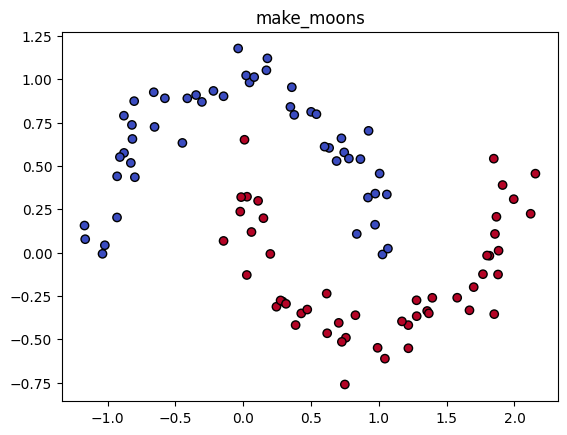

In [ ]:
# The data: two interleaving half-moons, a non-linearly-separable problem.
X, y = make_moons(n_samples=100, noise=0.1, random_state=1)
y = y * 2 - 1                      # labels in {-1, +1}

plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k")
plt.title("make_moons"); plt.show()

In [ ]:
def loss_fn(model, X, y, alpha=1e-4):
    scores = [model(list(map(Value, xi))) for xi in X]
    losses = [(1 - yi * si).relu() for yi, si in zip(y, scores)]
    data_loss = sum(losses) * (1.0 / len(losses))
    reg_loss = alpha * sum((p * p for p in model.parameters()))
    acc = sum((yi > 0) == (si.data > 0) for yi, si in zip(y, scores)) / len(y)
    return data_loss + reg_loss, acc

In [ ]:
# Gradient check on a tiny network first.
# Verify that gradients for every parameter of a small net match finite differences.

seed_everything(0)
tiny = MLPValue(2, [3, 1])
Xs, ys = X[:5], y[:5]

total, _ = loss_fn(tiny, Xs, ys)
tiny.zero_grad()
total.backward()

worst = 0.0
for p in tiny.parameters():
    old, h = p.data, 1e-6
    p.data = old + h; f_plus = loss_fn(tiny, Xs, ys)[0].data
    p.data = old - h; f_minus = loss_fn(tiny, Xs, ys)[0].data
    p.data = old
    worst = max(worst, rel_error(p.grad, (f_plus - f_minus) / (2 * h)))
print("worst relative error:", worst)

worst relative error: 6.9315106210965185e-09


In [ ]:
# Train it. The manual update is plain gradient descent with a decaying learning rate: p ← p − lr · grad.

seed_everything(1)
model = MLPValue(2, [8, 8, 1])
print("parameters:", len(model.parameters()))

n_steps = 100
for k in range(n_steps):
    total, acc = loss_fn(model, X, y)
    model.zero_grad()
    total.backward()

    lr = 1.0 - 0.9 * k / n_steps
    for p in model.parameters():
        p.data -= lr * p.grad

    if k % 20 == 0 or k == n_steps - 1:
        print(f"step {k:3d} | loss {total.data:.4f} | acc {acc:.2f}")

parameters: 105
step   0 | loss 0.4107 | acc 0.77
step  20 | loss 0.2614 | acc 0.88
step  40 | loss 0.2145 | acc 0.90
step  60 | loss 0.1173 | acc 0.97
step  80 | loss 0.0615 | acc 0.98
step  99 | loss 0.0495 | acc 0.99


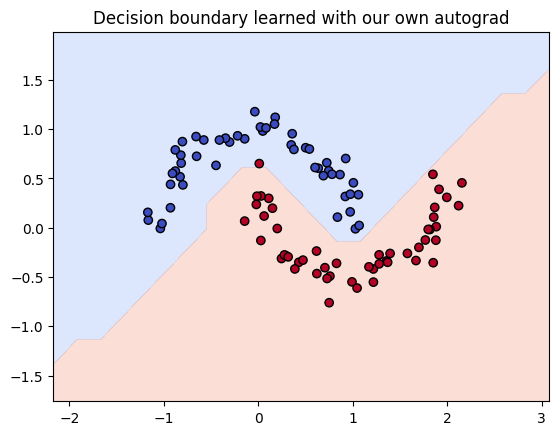

In [ ]:
# Decision boundary

h = 0.25
xx, yy = np.meshgrid(np.arange(X[:, 0].min() - 1, X[:, 0].max() + 1, h),
                     np.arange(X[:, 1].min() - 1, X[:, 1].max() + 1, h))
grid = np.c_[xx.ravel(), yy.ravel()]
scores = np.array([model(list(map(Value, row))).data for row in grid])
Z = (scores > 0).reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k")
plt.title("Decision boundary learned with our own autograd"); plt.show()

---

## Part 6: Optimizers

Here are the four update rules (*g = gradient, lr = learning rate, t = step count*).

*SGD: p ← p − lr·g*

*SGD with momentum*: keep a velocity that accumulates past gradients, which smooths noise and speeds up along consistent directions.

*v ← μ·v + g*

*p ← p − lr·v          (μ is typically 0.9)*

*RMSprop*: divide each parameter’s step by a running RMS of its recent gradients, so parameters with huge gradients take smaller steps.

*s ← α·s + (1−α)·g²*

*p ← p − lr · g / (√s + ε)*

*Adam*: momentum (first moment m) plus RMSprop-style scaling (second moment v), with bias correction. Both m and v start at 0, so early on they’re biased toward zero. Dividing by 1 − βᵗ fixes that.

*m ← β1·m + (1−β1)·g*

*v ← β2·v + (1−β2)·g²*

*m̂ = m / (1−β1ᵗ)        v̂ = v / (1−β2ᵗ)*

*p ← p − lr · m̂ / (√v̂ + ε)*

Defaults: *β1 = 0.9, β2 = 0.999, ε = 1e-8*.

Adam vs AdamW: “weight decay” and “L2 regularization” are the same thing for plain SGD, but not for Adam.

*Adam + L2*: add *wd·p* to the gradient. That term then passes through the adaptive scaling, so the decay strength varies per parameter.

*AdamW*: shrink the weights directly, *p ← p·(1 − lr·wd)*, separately from the gradient step. That’s why AdamW is the default for transformers.

---

## Part 7: Optimizers in NumPy

In [ ]:
class Optimizer:
    def __init__(self, params, lr):
        self.params = params
        self.lr = lr
        self.t = 0

    def step(self, grads):
        raise NotImplementedError


class SGD(Optimizer):
    def __init__(self, params, lr=1e-2, momentum=0.0):
        super().__init__(params, lr)
        self.momentum = momentum
        self.buf = [np.zeros_like(p) for p in params]

    def step(self, grads):
        self.t += 1
        for p, g, b in zip(self.params, grads, self.buf):
            if self.momentum:
                b *= self.momentum
                b += g
                p -= self.lr * b
            else:
                p -= self.lr * g


class RMSprop(Optimizer):
    def __init__(self, params, lr=1e-2, alpha=0.99, eps=1e-8):
        super().__init__(params, lr)
        self.alpha, self.eps = alpha, eps
        self.sq = [np.zeros_like(p) for p in params]

    def step(self, grads):
        self.t += 1
        for p, g, s in zip(self.params, grads, self.sq):
            s *= self.alpha
            s += (1 - self.alpha) * g * g
            p -= self.lr * g / (np.sqrt(s) + self.eps)


class Adam(Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8,
                 weight_decay=0.0, decoupled=False):
        super().__init__(params, lr)
        self.betas, self.eps = betas, eps
        self.weight_decay, self.decoupled = weight_decay, decoupled
        self.m = [np.zeros_like(p) for p in params]
        self.v = [np.zeros_like(p) for p in params]

    def step(self, grads):
        self.t += 1
        b1, b2 = self.betas
        for p, g, m, v in zip(self.params, grads, self.m, self.v):
            if self.weight_decay:
                if self.decoupled:
                    p *= 1 - self.lr * self.weight_decay      # AdamW: shrink weights directly
                else:
                    g = g + self.weight_decay * p             # Adam + L2: add to the gradient
            m *= b1
            m += (1 - b1) * g
            v *= b2
            v += (1 - b2) * g * g
            m_hat = m / (1 - b1 ** self.t)
            v_hat = v / (1 - b2 ** self.t)
            p -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)


class AdamW(Adam):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2):
        super().__init__(params, lr, betas, eps, weight_decay, decoupled=True)

---

## Part 8: Verify against torch.optim

We run our optimizer and PyTorch’s side by side on the Rosenbrock function (a banana-shaped valley with its minimum at (1, 1)), in *float64*, feeding both the same gradient each step.

In [ ]:
def rosenbrock_torch(p):
    x, y = p[0], p[1]
    return (1 - x) ** 2 + 100 * (y - x ** 2) ** 2

def compare(our_cls, our_kw, torch_cls, torch_kw, steps=200, start=(-1.5, 2.0)):
    p_np = np.array(start, dtype=np.float64)
    ours = our_cls([p_np], **our_kw)

    p_t = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    ref = torch_cls([p_t], **torch_kw)

    max_diff = 0.0
    for _ in range(steps):
        ref.zero_grad()
        rosenbrock_torch(p_t).backward()
        g = p_t.grad.detach().numpy().copy()
        ref.step()
        ours.step([g])
        max_diff = max(max_diff, np.abs(p_np - p_t.detach().numpy()).max())
    return max_diff

tests = {
    "SGD":             (SGD,     dict(lr=1e-3),                       torch.optim.SGD,     dict(lr=1e-3)),
    "SGD+momentum":    (SGD,     dict(lr=1e-3, momentum=0.9),         torch.optim.SGD,     dict(lr=1e-3, momentum=0.9)),
    "RMSprop":         (RMSprop, dict(lr=5e-3),                       torch.optim.RMSprop, dict(lr=5e-3)),
    "Adam":            (Adam,    dict(lr=1e-2),                       torch.optim.Adam,    dict(lr=1e-2)),
    "Adam + L2 (0.1)": (Adam,    dict(lr=1e-2, weight_decay=0.1),     torch.optim.Adam,    dict(lr=1e-2, weight_decay=0.1)),
    "AdamW (0.1)":     (AdamW,   dict(lr=1e-2, weight_decay=0.1),     torch.optim.AdamW,   dict(lr=1e-2, weight_decay=0.1)),
}

for name, (oc, ok, tc, tk) in tests.items():
    print(f"{name:18s} max |ours - torch| = {compare(oc, ok, tc, tk):.2e}")

SGD                max |ours - torch| = 0.00e+00
SGD+momentum       max |ours - torch| = 2.50e-16
RMSprop            max |ours - torch| = 0.00e+00
Adam               max |ours - torch| = 2.22e-16
Adam + L2 (0.1)    max |ours - torch| = 0.00e+00
AdamW (0.1)        max |ours - torch| = 0.00e+00


---

## Part 9: Watch them race

Rosenbrock’s valley is easy to enter but slow to follow, and that is where optimizers differ. We use the analytic gradient *∂f/∂x = −2(1−x) − 400x(y−x²)* and *∂f/∂y = 200(y−x²)*.

In [ ]:
def rosen(p):
    x, y = p
    return (1 - x) ** 2 + 100 * (y - x ** 2) ** 2

def rosen_grad(p):
    x, y = p
    return np.array([-2 * (1 - x) - 400 * x * (y - x ** 2), 200 * (y - x ** 2)])

def run(opt_cls, steps, start=(-1.5, 2.0), **kw):
    p = np.array(start, dtype=np.float64)
    opt = opt_cls([p], **kw)
    path = [p.copy()]
    for _ in range(steps):
        opt.step([rosen_grad(p)])
        path.append(p.copy())
    return np.array(path)

configs = {
    "SGD (lr 2e-3)":          (SGD,     dict(lr=2e-3)),
    "Momentum (lr 1e-3)":     (SGD,     dict(lr=1e-3, momentum=0.9)),
    "RMSprop (lr 5e-3)":      (RMSprop, dict(lr=5e-3)),
    "Adam (lr 5e-2)":         (Adam,    dict(lr=5e-2)),
}
paths = {name: run(cls, 2000, **kw) for name, (cls, kw) in configs.items()}

for name, path in paths.items():
    print(f"{name:22s} final point {path[-1].round(3)}  f = {rosen(path[-1]):.2e}")

SGD (lr 2e-3)          final point [0.993 0.987]  f = 4.57e-05
Momentum (lr 1e-3)     final point [1. 1.]  f = 1.36e-08
RMSprop (lr 5e-3)      final point [0.94  0.891]  f = 8.56e-03
Adam (lr 5e-2)         final point [1. 1.]  f = 1.73e-12


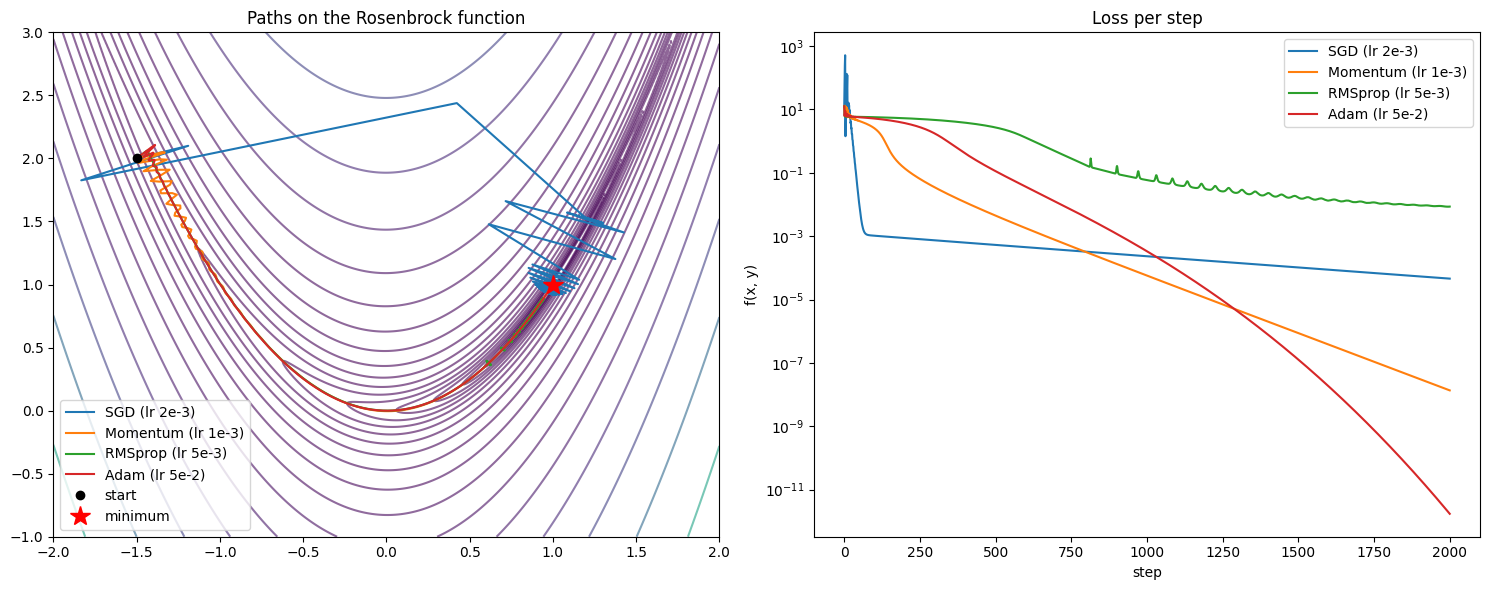

In [ ]:
xs, ys = np.linspace(-2, 2, 400), np.linspace(-1, 3, 400)
XX, YY = np.meshgrid(xs, ys)
ZZ = (1 - XX) ** 2 + 100 * (YY - XX ** 2) ** 2

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].contour(XX, YY, ZZ, levels=np.logspace(-1, 3.5, 20), cmap="viridis", alpha=0.6)
for name, path in paths.items():
    ax[0].plot(path[:, 0], path[:, 1], label=name, linewidth=1.5)
ax[0].plot(*paths["Adam (lr 5e-2)"][0], "ko", label="start")
ax[0].plot(1, 1, "r*", markersize=15, label="minimum")
ax[0].set_title("Paths on the Rosenbrock function"); ax[0].legend()

for name, path in paths.items():
    ax[1].plot([rosen(p) for p in path], label=name)
ax[1].set_yscale("log"); ax[1].set_xlabel("step"); ax[1].set_ylabel("f(x, y)")
ax[1].set_title("Loss per step"); ax[1].legend()
plt.tight_layout(); plt.show()

---

## Part 10: Our own AdamW inside the Day 1 Trainer

NumPy optimizers can’t train a PyTorch model, so we write the same *AdamW* as a *torch.optim.Optimizer* subclass.

In [ ]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            beta1, beta2 = group["betas"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                state = self.state[p]
                if not state:
                    state["step"] = 0
                    state["m"] = torch.zeros_like(p)
                    state["v"] = torch.zeros_like(p)

                state["step"] += 1
                t = state["step"]
                g = p.grad

                p.mul_(1 - group["lr"] * group["weight_decay"])          # decoupled decay
                state["m"].mul_(beta1).add_(g, alpha=1 - beta1)
                state["v"].mul_(beta2).addcmul_(g, g, value=1 - beta2)

                m_hat = state["m"] / (1 - beta1 ** t)
                v_hat = state["v"] / (1 - beta2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(group["eps"]), value=-group["lr"])
        return loss

In [ ]:
# A fair comparison. Both runs must see the same init and the same data order,
# so we rebuild the loaders from a fixed seed each time, and define the same small MLP as Day 1.

class MLP(nn.Module):
    def __init__(self, in_features=28 * 28, hidden=(256, 128), num_classes=10, dropout=0.2):
        super().__init__()
        layers = [nn.Flatten()]
        prev = in_features
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def get_loaders(seed=0, batch_size=128):
    tfm = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.2860,), (0.3530,))])
    full = datasets.FashionMNIST(root="data", train=True, download=True, transform=tfm)
    split_gen = torch.Generator().manual_seed(seed)
    train_set, val_set = random_split(full, [55_000, 5_000], generator=split_gen)
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True,
                              generator=torch.Generator().manual_seed(seed))
    val_loader = DataLoader(val_set, batch_size=256)
    return train_loader, val_loader


def train_with(optimizer_name):
    seed_everything(0)
    train_loader, val_loader = get_loaders(seed=0)
    model = MLP()
    cfg = TrainConfig(epochs=5, patience=0, ckpt_dir=f"ckpt_d2_{optimizer_name}")
    if optimizer_name == "torch":
        opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    else:
        opt = MyAdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    trainer = Trainer(model, train_loader, val_loader, cfg, optimizer=opt)
    _ = trainer.fit()
    return trainer.history

In [ ]:
hist_torch = train_with("torch")
hist_mine = train_with("mine")

print("\nval loss per epoch")
for i, (a, b) in enumerate(zip(hist_torch["val_loss"], hist_mine["val_loss"]), 1):
    print(f"epoch {i}: torch {a:.5f} | mine {b:.5f} | diff {abs(a - b):.1e}")

100%|██████████| 26.4M/26.4M [00:01<00:00, 19.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 307kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.64MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.5MB/s]


epoch 01/5 | train loss 0.9551 acc 0.6930 | val loss 0.4372 acc 0.8408 | lr 7.61e-04 | 14.0s *
epoch 02/5 | train loss 0.4369 acc 0.8419 | val loss 0.3825 acc 0.8558 | lr 9.50e-04 | 16.6s *
epoch 03/5 | train loss 0.3719 acc 0.8635 | val loss 0.3353 acc 0.8744 | lr 6.10e-04 | 12.7s *
epoch 04/5 | train loss 0.3220 acc 0.8815 | val loss 0.3171 acc 0.8810 | lr 1.87e-04 | 12.3s *
epoch 05/5 | train loss 0.2940 acc 0.8927 | val loss 0.3065 acc 0.8864 | lr 5.09e-09 | 12.4s *
epoch 01/5 | train loss 0.9551 acc 0.6931 | val loss 0.4353 acc 0.8414 | lr 7.61e-04 | 13.1s *
epoch 02/5 | train loss 0.4368 acc 0.8414 | val loss 0.3839 acc 0.8534 | lr 9.50e-04 | 12.3s *
epoch 03/5 | train loss 0.3720 acc 0.8638 | val loss 0.3330 acc 0.8762 | lr 6.10e-04 | 12.3s *
epoch 04/5 | train loss 0.3218 acc 0.8816 | val loss 0.3139 acc 0.8834 | lr 1.87e-04 | 12.1s *
epoch 05/5 | train loss 0.2945 acc 0.8934 | val loss 0.3064 acc 0.8876 | lr 5.09e-09 | 12.5s *

val loss per epoch
epoch 1: torch 0.43716 | mine 

In [ ]:
# Expect a number far below 1e-5
torch.manual_seed(0)
m1, m2 = MLP(dropout=0.0), MLP(dropout=0.0)
m2.load_state_dict(m1.state_dict())
o1 = torch.optim.AdamW(m1.parameters(), lr=1e-3, weight_decay=1e-2)
o2 = MyAdamW(m2.parameters(), lr=1e-3, weight_decay=1e-2)
x, y = torch.randn(64, 1, 28, 28), torch.randint(0, 10, (64,))
for _ in range(5):
    for m, o in ((m1, o1), (m2, o2)):
        o.zero_grad()
        nn.CrossEntropyLoss()(m(x), y).backward()
        o.step()
print(max((a - b).abs().max().item() for a, b in zip(m1.parameters(), m2.parameters())))

1.4081597328186035e-06
